Student Name: Muneeb Rifaq

CMS ID: (45 45 38)

##### Faculty of Computing

#### CS-405 Deep Learning

##**Lab 4 - Open Ended Lab**  
**CLO 4,3**  
**Date: 2-10-2026**  

**Lab Engineer:** Ms. Areeba Rameen  
**Instructor:** Dr. Muhammad Daud Abdullah

---

**Goal**: Learn how to construct an autograd graph and implementing a basic engine to get the intuition of the autograd engine framework.

**Lab Objectives**
By the end of this lab, students will be able to:

1. Understand the concept of a computational graph in neural networks.
2. Implement a basic Node structure to store values and gradients.
3. Perform forward-pass operations while building a computation graph.
4. Apply backward propagation using the chain rule to compute gradients.
5. Understand how automatic differentiation works in deep learning frameworks.
6. Implement common activation functions


**Credits: Prepared by**:
- John Liu
- Michael Kireeff

**Extra resources**: https://youtu.be/pnjkqSQMHmA?si=3Wrk-phsVBtNID1H [Follow this link for this lab]

For students wondering why are they being forced to learn and implement backpropagation from scratch, follow this interesting blog link for the answer: https://karpathy.medium.com/yes-you-should-understand-backprop-e2f06eab496b

**For submission: For each solution you provide, include your thought process—how you understood the problem—followed by your explanation of the solution in your own words. Your lab will be evaluated based on the effort demonstrated in your submitted notebook.**

**Plan**:
1. How to
   - Initialization
   - Basic Operations
   - Matrix Multiplication
   - Backward Function
   - SoftPlus
   - Leaky Relu
   - Tanh

#**Basic Node Class**

**Node Class:**
The Node class represents a single element in a computational graph. Each node stores a numerical value (data), its gradient (grad), and references to its parent nodes. This structure allows us to track how values are computed and how gradients should flow backward. The Node class forms the foundation of the autograd engine.

- We will suggest you do this in numpy (it is way easier).
- When initializing some of these arrays look into the Numpy library: https://numpy.org/doc/2.1/reference/generated/numpy.array.html
and understand there are some other interesting things (Understanding functions will be crucial to understand for HW2).

In [1]:
import numpy as np

class Node():
    def __init__(self, data, _parents=()):
        """
        We want to initialize data, grad, and backward.
        where:
            data is an array, do we have data?
            grad is an array, do we have gradients?
            _prev is a set, which one of our inputs holds the previous nodes?
        """
        #TODO: Hold data in a np.array(), initialize grad to the same shape as data with values of 0, and keep track of parents in a list or set
        self.data = np.array(data)
        self.grad = np.zeros_like(self.data)
        self._parents = set(_parents)

    def __repr__(self): # this just overloads the __repr__ operation so it allows nodes to be printed in this format.
        return f"Node(data={self.data}, grad={self.grad})"

### Base Node Tests

In [2]:
print("Testing Node Initialization...")
a_test = Node(3.0)
b_test = Node(2.0)

assert a_test.data == 3.0, "Error: a_test.data not set correctly"
assert b_test.data == 2.0, "Error: b_test.data not set correctly"
assert a_test.grad == 0.0, "Error: a_test.grad not set correctly"
assert b_test.grad == 0.0, "Error: b_test.grad not set correctly"

print("Passed!")

Testing Node Initialization...
Passed!


**What I learned from this Solution:**

What autocad is in the simplest terms is a way to represent a neural networks nodes and decision making chains in a simple way that allows you to modularly create them and assign them in chains such that it becomes easy and simple to link them and perform forward and backward operations.

Base Node Class remember **3** things:
- The data that is stored inside the node itself(int, float, etc)
- The parents of that node
- The gradient of the nodes operation.

#**Checkin \#1**


  Question: What is the point of autograd?
  <details>
  Answer: To incrementally add operations so that it can all be automatically differentiated,
  </details>

#**Elementary functions/ combinations**


## Add Operation

The addition operation combines two nodes element-wise and produces a new output node. During the forward pass, the data values are added. During the backward pass, gradients are distributed equally to both parent nodes. This demonstrates how simple mathematical operations can define their own gradient rules.

In [3]:
def add_node(a_node, b_node):
    """
    Element-wise addition: A + B
    """
    # TODO:
    # Produce a new node:
    #   Add the input data together to produce the output for the out node.
    #   Make sure the output knows what its parents are
    out = Node(a_node.data + b_node.data, _parents=(a_node, b_node))

    # Note:
    # - out.grad will be populated later
    # - for now, assume out.grad has its proper value for this node.
    #
    # TODO:
    # define a backward_fn to update a_node's gradients and b_node's gradients
    # based on out.grad
    #
    def add_backward():
        a_node.grad += out.grad
        # Derivative of (A + B) with respect to B is 1, so dL/dB = dL/dOut * 1
        b_node.grad += out.grad

    out.backward_fn = add_backward

    return out

### Add Operation Tests

In [4]:
# Test your add operation
a_test = Node(3.0)
b_test = Node(2.0)

print("Testing Node Addition...")
c_test = add_node(a_test, b_test)
assert c_test.data == 5.0, "Error: add_node DATA not evaluated correctly"
assert c_test.grad == 0.0, "Error: add_node GRAD not initialized correctly"
print("Passed!")

print("Testing Node Addition Backward...")
c_test.grad = 1.0
c_test.backward_fn()
assert a_test.grad == 1.0, "Error: add_node BACKWARD does not update parent gradients correctly"
assert b_test.grad == 1.0, "Error: add_node BACKWARD does not update parent gradients correctly"

print("Passed!")

print("All tests passed!")

Testing Node Addition...
Passed!
Testing Node Addition Backward...
Passed!
All tests passed!


**What I learned from this Solution:**

What the Add node is simply a way to construct a basic Addition Style Operation using 3 nodes A, B and C where the operation is:
(A + B => C)

In addition to basic Node operations, Add Node remembers 2 things:
- The method formula to perform forward propogation
- The method to perform backpropogation for weight updation.

Returns: Created node that is connected to 2 parent nodes and has data of the addition of parents data.

Base Node Class remember **5** things:
- The data that is stored inside the node itself(int, float, etc)
- The parents of that node
- The method formula to perform forward propogation
- The gradient of the nodes operation.
- The method to perform backpropogation for weight updation.

## Mul Operation

The multiplication operation performs element-wise multiplication between two nodes. In the backward pass, the gradient of each parent depends on the value of the other parent (according to the product rule). This introduces students to how derivatives are computed using calculus rules.

In [5]:
def mul_node(a_node, b_node):
    """
    Element-wise multiplication: A * B
    """
    # TODO:
    # Produce a new node:
    #   Make sure the output's data is correct
    #   Make sure the output knows what its parents are
    out = Node(a_node.data * b_node.data, _parents=(a_node, b_node))


    # Note:
    # - out.grad will be populated later
    # - for now, assume out.grad has its proper value for this node.
    #
    # TODO:
    # define a backward_fn to update a_node's gradients and b_node's gradients
    # based on out.grad
    #
    def mul_backward():
        a_node.grad += b_node.data * out.grad
        b_node.grad += a_node.data * out.grad

    out.backward_fn = mul_backward

    return out

### Mul Operation Tests

In [6]:
# Test your multiplication operation
a_test = Node(3.0)
b_test = Node(2.0)

print("Testing Node Multiplication...")
d_test = mul_node(a_test, b_test)
assert d_test.data == 6.0, "Error: mul_node DATA not evaluated correctly"
assert d_test.grad == 0.0, "Error: mul_node GRAD not initialized correctly"

print("Passed!")


print("Testing Node Multiplication Backward...")
d_test.grad = 1.0
d_test.backward_fn()
assert a_test.grad == 2.0, "Error: mul_node BACKWARD does not update parent gradients correctly"
assert b_test.grad == 3.0, "Error: mul_node BACKWARD does not update parent gradients correctly"

print("Passed!")

print("All tests passed!")


Testing Node Multiplication...
Passed!
Testing Node Multiplication Backward...
Passed!
All tests passed!


## **Checkin #2**

Question: Why is it important to have these elementary functions before going to more complex functions?
<details>
Answer: All complex functions require basic elementary functions to work. So instead of having to code backward each function, we can just call backward of these passed modules.
</details>

**What I learned from this Solution:**

What the Multiply node is simply a way to construct a basic Multiplication Style Operation using 3 nodes A, B and C where the operation is:
(A * B => C)
This node will be used in sets and chained to perform more complex calculations down the road.

In addition to basic Node operations, Multiply Node remembers 2 things:
- The method formula to perform forward propogation(A * B)
- The method to perform backpropogation for weight updation. (A_grad = A_grad + B_data*C_grad)

Returns: Created node that is connected to 2 parent nodes and has data of the multiplication of parents data.



# **Meme #1**

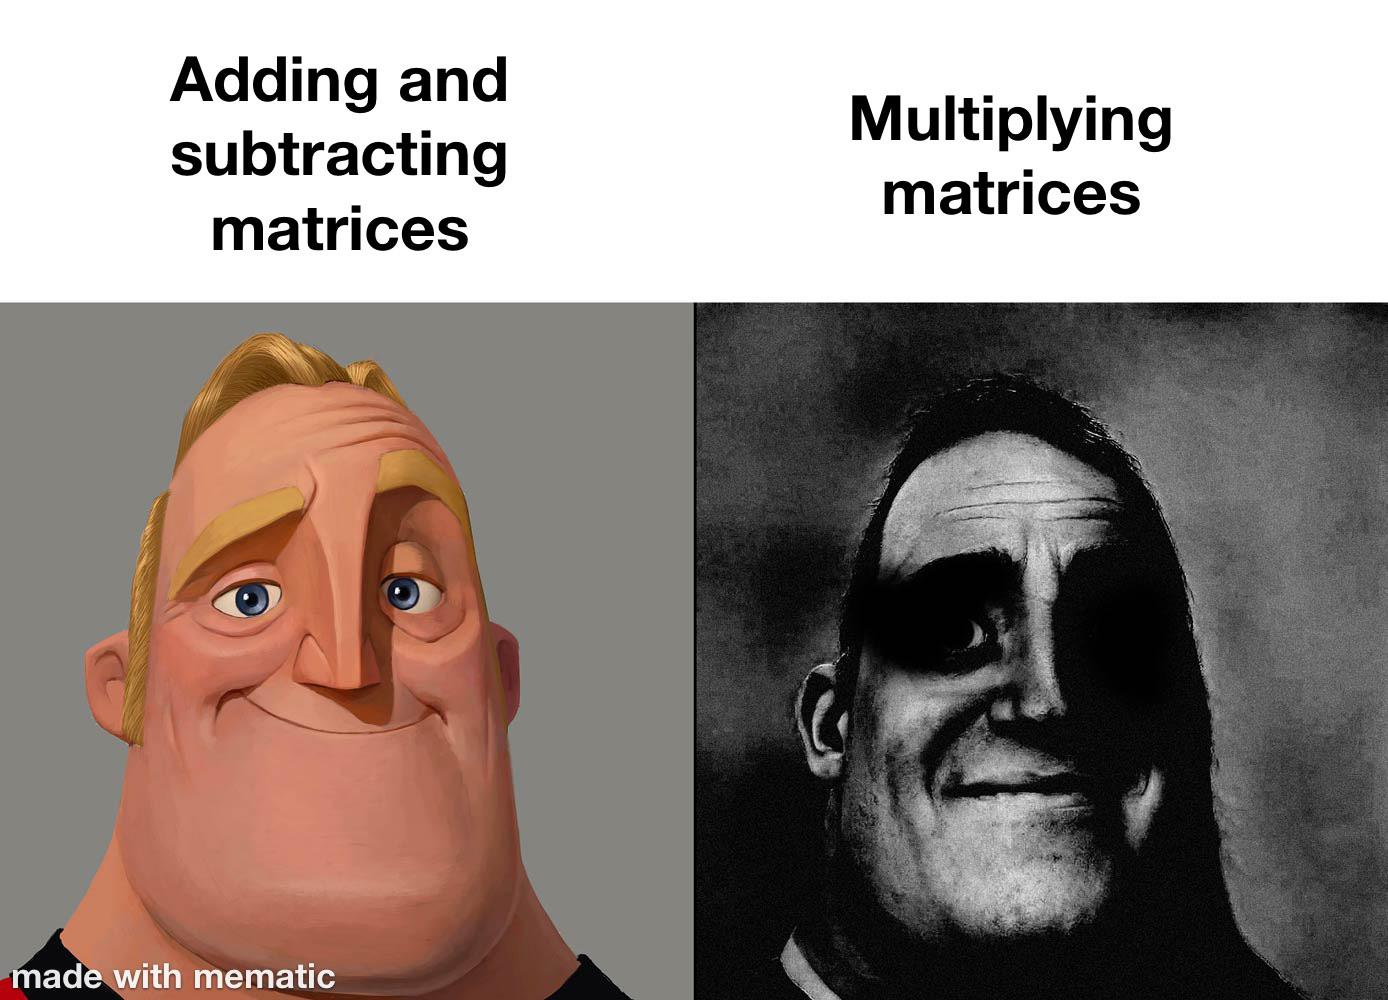

#Matrix Multiplication

Matrix multiplication extends the concept of multiplication to higher dimensions. It is a fundamental operation in neural networks, especially in fully connected layers. The backward pass requires applying matrix derivative rules, showing how gradients are computed in multi-dimensional cases.

In [7]:
def matmul_node(a_node, b_node):
    """Matrix multiplication: A @ B"""

    # TODO

    out = Node(a_node.data @ b_node.data, _parents= (a_node, b_node))

    # define backward function using matmultiply derivs
    def matmul_backward():
      a_node.grad += out.grad @ b_node.data.T

      b_node.grad += a_node.data.T @ out.grad

    out.backward_fn = matmul_backward

    return out

### Tests matmul function

In [8]:
a_test = Node(np.array([[1, 2], [3, 4]]))
b_test = Node(np.array([[2, 0], [1, 2]]))

print("Testing Matrix Multiplication...")
c_test = matmul_node(a_test, b_test)

assert np.allclose(c_test.data, np.array([[4, 4], [10, 8]])), "Error: matmul DATA not evaluated correctly"
print("Passed!")

print("Testing Matrix Multiplication Backward...")
c_test.grad = np.array([[1, 1], [1, 1]])
c_test.backward_fn()

assert np.allclose(a_test.grad, np.array([[2, 3], [2, 3]])), "Error: matmul BACKWARD does not update parent gradients correctly"
assert np.allclose(b_test.grad, np.array([[4, 4], [6, 6]])), "Error: matmul BACKWARD does not update parent gradients correctly"
print("Passed!")

print("All tests passed!")

Testing Matrix Multiplication...
Passed!
Testing Matrix Multiplication Backward...
Passed!
All tests passed!


**What I learned from this Solution:**

What the Multiply node is simply a way to construct a more complex Matrix Multiplication Style Operation using 3 nodes A, B and C where the operation is:
(A * B => C)
What is different from this yo standard add node is that the Input nodes contain entire matrixes that have to multiplied together so standard add node will not work


This will be espetially useful when performing Batch gradient descent which will need matrix multioplication for forward propogationa so this will be needed.



#**Meme #2**

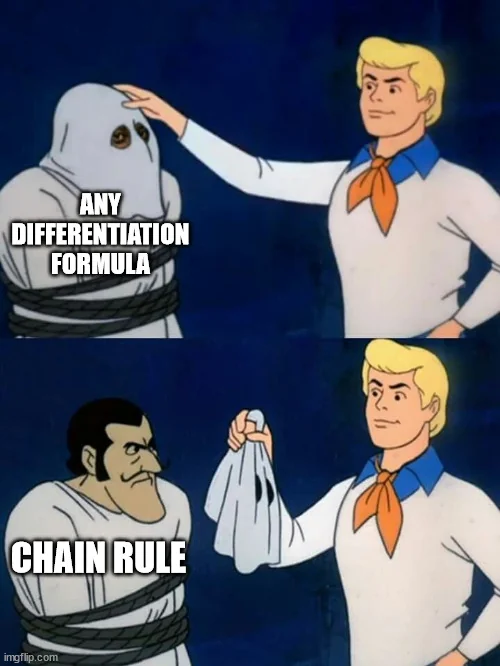

**What I learned from this Solution:**

What the Multiply node is simply a way to construct a basic Multiplication Style Operation using 3 nodes A, B and C where the operation is:
(A * B => C)
This node will be used in sets and chained to perform more complex calculations down the road.

In addition to basic Node operations, Multiply Node remembers 2 things:
- The method formula to perform forward propogation(A * B)
- The method to perform backpropogation for weight updation. (A_grad = A_grad + B_data*C_grad)

Returns: Created node that is connected to 2 parent nodes and has data of the multiplication of parents data.

Base Node Class remember **5** things:
- The data that is stored inside the node itself(int, float, etc)
- The parents of that node
- The method formula to perform forward propogation
- The gradient of the nodes operation.
- The method to perform backpropogation for weight updation.

# **Backward Method**
The backward method performs gradient propagation through the entire computational graph. It recursively traverses all parent nodes in reverse order and applies the chain rule to compute gradients. This step simulates how loss.backward() works in deep learning frameworks.


In [9]:
class Node(Node):
    def backward(self):
        backward_list = [] # Initialize backward list

        self.grad = np.ones_like(self.data)  # Placeholder for the gradient of the loss

        #TODO: Define a recursive function to build the backward list
        def build_backward_list(n):
            # TODO: Check if the node is in the backward list
            if n in backward_list:
                return

            # TODO: Add the node to the backward list
            backward_list.append(n)

            # TODO: iterate through the parents of the node and call the function recursively
            for parent in n._parents:
                build_backward_list(parent)

        # TODO: Call the recursive function to build the backward list
        build_backward_list(self)

        # TODO: print the output backward list if you want to see it!
        print(backward_list)

        # TODO: Iterate through the backward list and call each backward_fn (if it has parents)
        for node in backward_list:
            backward_fn = getattr(node, 'backward_fn', None)
            if backward_fn is not None:
                backward_fn()

###Backward Test

In [10]:
a_test = Node(3)
b_test = Node(2)

c_test = add_node(a_test, b_test)
f_test = mul_node(c_test, b_test)


print("Testing Node BACKWARD...")
f_test.grad = 1.0
f_test.backward()

print(f"a_grad: {a_test}")
print(f"b_grad: {b_test}")
print(f"c_grad: {c_test}")
print(f"f_grad: {f_test}")

assert a_test.grad == 2.0, "Error: BACKWARD does not update parent gradients correctly"
assert b_test.grad == 7.0, "Error: BACKWARD does not update parent gradients correctly"
assert c_test.grad == 2.0, "Error: BACKWARD does not update parent gradients correctly"
assert f_test.grad == 1.0, "Error: BACKWARD does not update parent gradients correctly"

print("All tests passed!")

Testing Node BACKWARD...
[Node(data=10, grad=1), Node(data=2, grad=0), Node(data=5, grad=0), Node(data=3, grad=0)]
a_grad: Node(data=3, grad=2)
b_grad: Node(data=2, grad=7)
c_grad: Node(data=5, grad=2)
f_grad: Node(data=10, grad=1)
All tests passed!


## **Checkin 3**


Question: Why do we need a backward pass? \\
**Hint:**
Look at Meme #2
<details>
Answer: Because if we have many layers, than we need loop through them all.
</details>


**What I learned from this Solution:**

This new setup is an extension of the absic node class in a way that allows a neural network to instantly and easily perform backpropogation of the entire chain from last node to first ones.

The importance of this new Backwards method is simple.

- It allows the neural network to quickly aand efficiently peform backward propogation to update weights
- It can save a lot of time and effort especially in a proper neural network application with milions of nodes and weights.

##**Meme #3**

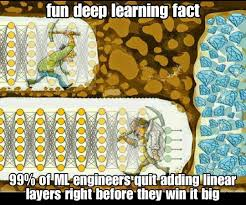

# **Activation Functions**


* For these, you will want to use your primitives (mul_node, add_node, as well as some others we're about to give you).
* This is so that in the final output, all you simply have to do is call out.backward() and all the derivatives will be computed for you!

##**Softplus**
Softplus is a smooth, differentiable alternative to ReLU. It is defined as ln(1 + e^x). In this section, students implement Softplus using previously defined primitive operations. This demonstrates how complex functions can be constructed from simple building blocks while still supporting automatic differentiation.

In [14]:
# Here's a natural log node for you :)
def log_node(a_node):
    out = Node(np.log(a_node.data), (a_node,))
    def backward_fn():
        a_node.grad += out.grad / a_node.data
    out.backward_fn = backward_fn
    return out

def exp_node(a_node):
    out = Node(np.exp(a_node.data), (a_node,))
    def backward_fn():
        a_node.grad += out.grad * out.data
    out.backward_fn = backward_fn
    return out

In [15]:
def softplus_node(x):
    """
    softplus(x) = ln(1 + e^x)
    """
    # Create a compatible constant node matching the shape of x to avoid shape mismatch during broadcast backprop
    one_node = Node(np.ones_like(x.data))
    out = log_node(add_node(exp_node(x), one_node))
    return out

### Tests for SoftPlus

In [16]:
# Create a test input node (use a range of values for variety)
x = Node(np.array([-2.0, -1.0, 0.0, 1.0, 2.0]))  # A mix of negative and positive values
out = softplus_node(x)
expected_forward = np.log(1.0 + np.exp(x.data))

# Print results for forward pass
print("Forward Output (softplus(x)):", out.data)
print("Expected:", expected_forward)
print("Match:", np.allclose(out.data, expected_forward))


out.grad = np.ones_like(out.data)
out.backward()
expected_grad_x = 1.0 / (1.0 + np.exp(-x.data))  # Sigmoid function

# Print results for backward pass (gradients)
print("\nGradient wrt Input:", x.grad)
print("Expected Gradient:", expected_grad_x)
print("Match:", np.allclose(x.grad, expected_grad_x))


Forward Output (softplus(x)): [0.12692801 0.31326169 0.69314718 1.31326169 2.12692801]
Expected: [0.12692801 0.31326169 0.69314718 1.31326169 2.12692801]
Match: True
[Node(data=[0.12692801 0.31326169 0.69314718 1.31326169 2.12692801], grad=[1. 1. 1. 1. 1.]), Node(data=[1.13533528 1.36787944 2.         3.71828183 8.3890561 ], grad=[0. 0. 0. 0. 0.]), Node(data=[1. 1. 1. 1. 1.], grad=[0. 0. 0. 0. 0.]), Node(data=[0.13533528 0.36787944 1.         2.71828183 7.3890561 ], grad=[0. 0. 0. 0. 0.]), Node(data=[-2. -1.  0.  1.  2.], grad=[0. 0. 0. 0. 0.])]

Gradient wrt Input: [0.11920292 0.26894142 0.5        0.73105858 0.88079708]
Expected Gradient: [0.11920292 0.26894142 0.5        0.73105858 0.88079708]
Match: True


# **Checkin \#4**

Question: What are the memory implications for storing the Softplus forward-pass values in autograd?
<details>
Autograd systems often store forward-pass values for backprop. For Softplus, the output itself $ln(1+e^x)$ may be used to compute or simplify the gradient. So even functions like softplus, can use sigmoid to help simplify memory allocation.
</details>

**What I learned from this Solution:**

This new activation fucntion is called Softplus which is a faster and more differentiable alternative to Relu
Its function is ln(1 + e^x)

This will be espetially useful when speed of convergence and weight updation is important in large datasets and neural networks.



##**Meme \#4**

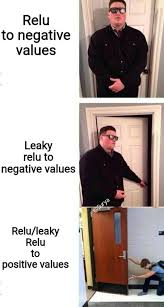

## **Leaky ReLU**
Leaky ReLU is a piecewise activation function that allows a small gradient for negative inputs. This section helps students understand how autograd handles piecewise-defined functions and how gradients are computed differently depending on the input region.

In [17]:
def leaky_relu_node(input, alpha=0.01):
    """
    Leaky ReLU activation:
        f(x) = x,         if x > 0
                alpha * x, otherwise
    """
    data = np.where(input.data > 0, input.data, alpha * input.data)
    out = Node(data, _parents=(input,))

    def backward_fn():
        dx = np.where(input.data > 0, 1.0, alpha)
        input.grad += out.grad * dx

    out.backward_fn = backward_fn
    return out

### Tests for Leaky ReLU

In [18]:
# Create a test input node
x = Node(np.array([-2.0, -1.0, 0.0, 1.0, 2.0]))  # A mix of negative and positive values
alpha = 0.01  # Leaky ReLU slope for negatives

# Compute Leaky ReLU
out = leaky_relu_node(x, alpha)

# Set the output gradient (simulating dL/dout = 1 for all elements)
out.grad = np.ones_like(out.data)

# Perform backpropagation
out.backward()

# Expected values
expected_forward = np.array([-0.02, -0.01, 0.0, 1.0, 2.0])  # Leaky ReLU applied
expected_grad_x = np.array([alpha, alpha, 1.0, 1.0, 1.0])  # Gradients from backprop

# Print results
print("Forward Output:", out.data)
print("Expected:", expected_forward)
print("Match:", np.allclose(out.data, expected_forward))

print("\nGradient wrt Input:", x.grad)
print("Expected Gradient:", expected_grad_x)
print("Match:", np.allclose(x.grad, expected_grad_x))


[Node(data=[-0.02 -0.01  0.    1.    2.  ], grad=[1. 1. 1. 1. 1.]), Node(data=[-2. -1.  0.  1.  2.], grad=[0. 0. 0. 0. 0.])]
Forward Output: [-0.02 -0.01  0.    1.    2.  ]
Expected: [-0.02 -0.01  0.    1.    2.  ]
Match: True

Gradient wrt Input: [0.01 0.01 0.01 1.   1.  ]
Expected Gradient: [0.01 0.01 1.   1.   1.  ]
Match: False


#**Checkin 5**


Question: How does autograd handle piecewise-defined functions (like Leaky ReLU)?
<details>
Answer: Activation functions such as ReLU are piecewise (i.e., different definitions in different ranges of input).
</details>


**What I learned from this Solution:**

Leaky relu Node is a spectial ndoe that can be placed in a neural network after a base calculation in order to perform an activation functiona and introduce non-linearity into the formula.

While traditional relu does not contribute any information to the gradient descent formula in the case of negative inputs, Leaky relu provides a small value that allows the gradient to benefit and improve on -ve values.

This will be espetially useful when the network might get a lot of -ve results and will need some context on how to improve.



## **Meme \#5**

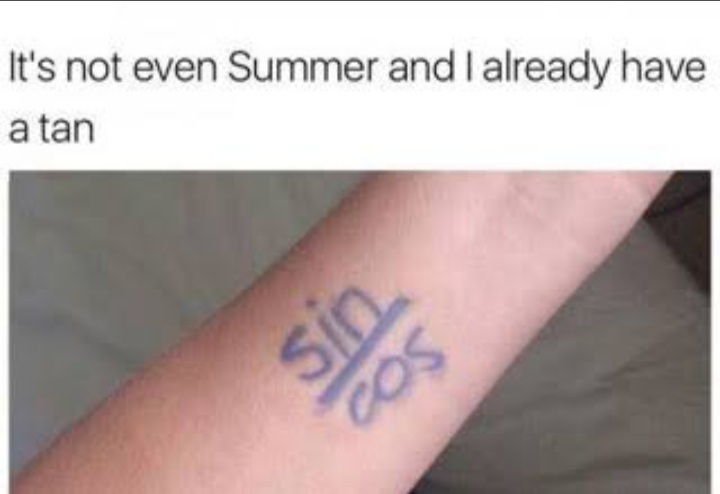

##**Tanh**
Tanh is a non-linear activation function that compresses input values between -1 and 1. Students implement Tanh using exponential and division primitives. This shows how intermediate values are used during backpropagation and how gradients depend on the forward-pass output.

In [19]:
# We'll be nice and give you a div_nodes and exp_nodes primitives :)
def div_node(a_node, b_node):
    out = Node(a_node.data / b_node.data, (a_node, b_node))
    def backward_fn():
        a_node.grad += out.grad / b_node.data
        b_node.grad += -out.grad * a_node.data / (b_node.data**2)
    out.backward_fn = backward_fn
    return out

In [20]:
def tanh_node(x):
    """
    tanh(x) = (e^x - e^-x) / (e^x + e^-x)
    """
    # Create constant nodes for -1 to perform negation via multiplication
    neg_one = Node(-1.0 * np.ones_like(x.data))

    # e^x and e^-x
    exp_pos = exp_node(x)
    exp_neg = exp_node(mul_node(x, neg_one))

    # Numerator: e^x - e^-x = e^x + (-1 * e^-x)
    neg_exp_neg = mul_node(exp_neg, neg_one)
    num = add_node(exp_pos, neg_exp_neg)

    # Denominator: e^x + e^-x
    den = add_node(exp_pos, exp_neg)

    # tanh = num / den
    out = div_node(num, den)
    return out

### Tests for Tanh  

In [21]:
# Create a test input node
x = Node(np.array([-2.0, -1.0, 0.0, 1.0, 2.0]))  # A mix of negative and positive values

# Compute tanh using our function
out = tanh_node(x)

# Expected forward values (using NumPy for verification)
expected_forward = np.tanh(x.data)

# Set the output gradient (simulating dL/dout = 1 for all elements)
out.grad = np.ones_like(out.data)

# Perform backpropagation
out.backward()

# # Expected gradients: d/dx tanh(x) = 1 - tanh^2(x)
expected_grad_x = 1.0 - expected_forward**2  # (1 - tanh^2(x))
print()

# Print results
print("Forward Output:", out.data)
print("Expected:", expected_forward)
print("Match:", np.allclose(out.data, expected_forward))

print("\nGradient wrt Input:", x.grad)
print("Expected Gradient:", expected_grad_x)
print("Match:", np.allclose(x.grad, expected_grad_x))


[Node(data=[-0.96402758 -0.76159416  0.          0.76159416  0.96402758], grad=[1. 1. 1. 1. 1.]), Node(data=[7.52439138 3.08616127 2.         3.08616127 7.52439138], grad=[0. 0. 0. 0. 0.]), Node(data=[0.13533528 0.36787944 1.         2.71828183 7.3890561 ], grad=[0. 0. 0. 0. 0.]), Node(data=[-2. -1.  0.  1.  2.], grad=[0. 0. 0. 0. 0.]), Node(data=[7.3890561  2.71828183 1.         0.36787944 0.13533528], grad=[0. 0. 0. 0. 0.]), Node(data=[ 2.  1. -0. -1. -2.], grad=[0. 0. 0. 0. 0.]), Node(data=[-1. -1. -1. -1. -1.], grad=[0. 0. 0. 0. 0.]), Node(data=[-7.25372082 -2.35040239  0.          2.35040239  7.25372082], grad=[0. 0. 0. 0. 0.]), Node(data=[-7.3890561  -2.71828183 -1.         -0.36787944 -0.13533528], grad=[0. 0. 0. 0. 0.])]

Forward Output: [-0.96402758 -0.76159416  0.          0.76159416  0.96402758]
Expected: [-0.96402758 -0.76159416  0.          0.76159416  0.96402758]
Match: True

Gradient wrt Input: [-0.92934918 -0.58002566  0.         -0.58002566 -0.92934918]
Expected Gradie

#**Checkin \#6**
Question: What intermediate values do autograd frameworks store for
tanh?
<details>
Answer: we can do $y = tanh(x)$ as the derivative of tanh is $1 - y^2$.
</details>

**What I learned from this Solution:**

The tanh is the best activation function discusse yet as its result is 0 centered, solve sthe prpblem of dying relu so neuron gradients do not die at extreme values and is extremely differentiable

It also produces output at -1 to 1 range.


It is very good for neural network for weight updation but the exp operations are very computationally expensive.

#**Meme #6**

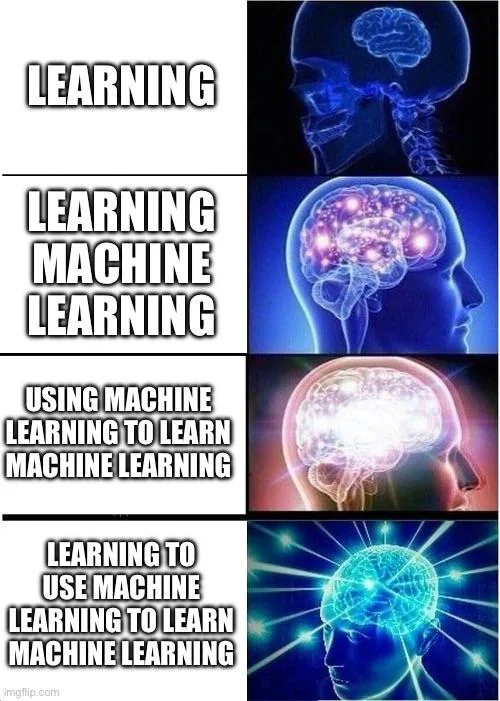

#**Meme #7**

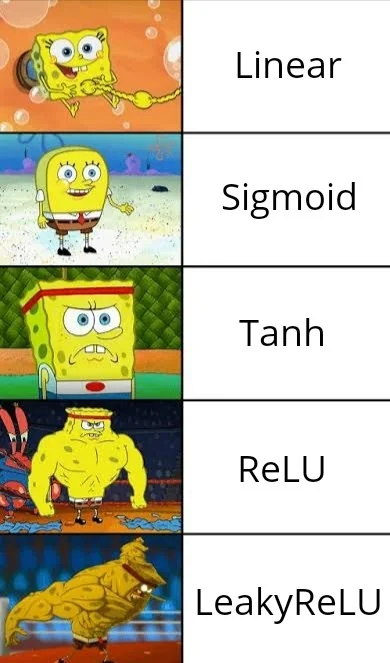

#**Further readings:**
* https://dlsyscourse.org/
* https://github.com/jax-ml/jax
* Baydin, Atilim Gunes, et al. "Automatic differentiation in machine learning: a
survey." Journal of Machine Learning Research 18 (2018): 1-43.